# Label-Blind GNSS Pairwise AoA Classifier: Best-m Diagnostic

This notebook applies a **degree-domain variant of the ephemeris-referenced AoA consistency detector** proposed in Section 3 of the journal draft while replacing temporal DP ambiguity resolution with an all-satellite `best-m` diagnostic. It assumes that the authentic and counterfeit PRNs are unknown during reconstruction and uses one manually configured static threshold in degrees.

The ordinary diagnostic does **not** use `SPOOF_SVIDS`, known-label reference filtering, or spoof-only epoch selection. The ephemeris-aligned best-m rule is applied identically to every eligible satellite, including spoofed satellites. Because target ephemeris participates in branch selection and again in residual evaluation, this is an ablation test for branch-selection failure—not an independent spoof detector. Controlled-experiment labels appear only in the post-hoc evaluation and explicitly label-leaking oracle-hybrid sections.

## Degree-domain pairwise decision rule with a best-m ambiguity ablation

For each eligible DD reference $r$, target $i$, and epoch $k$, the carrier-phase candidates are generated. In this diagnostic, one constant branch $m$ is selected per target/reference reconstruction by minimizing the median absolute difference between that candidate track and the target's ephemeris AoA. This deliberately replaces the journal's temporal DP/backtracking step.

For this experiment, the pairwise geometry residual is computed directly from AoA values in degrees:

$$q^{(r)}_{ij,k}[^{\circ}]=\left| (\widehat{\alpha}^{DD}_{i|r,k}-\widehat{\alpha}^{DD}_{j|r,k})-(\alpha^{eph}_{i,k}-\alpha^{eph}_{j,k}) \right|.$$

This is a degree-domain experimental variant, not the journal equation's direction-cosine residual. All reconstructed and ephemeris AoAs are in $[0^{\circ},180^{\circ}]$, so no circular-angle wrapping is required.

It is aggregated first over epochs and then over valid references:

$$\widetilde q^{(r)}_{ij}=\operatorname{median}_k q^{(r)}_{ij,k},\qquad \overline q_{ij}=\operatorname{median}_{r\ne i,j}\widetilde q^{(r)}_{ij}.$$

For this experiment, $\tau_p$ is set directly in degrees by `PAIRWISE_RESIDUAL_THRESHOLD_DEG`; it is not estimated from a GMM or calibration dataset. The consistency matrix, satellite score, and decision are

$$A_{ij}=\mathbf{1}[\overline q_{ij}\le\tau_p],\qquad C_i=\frac{1}{|S|-1}\sum_{j\ne i}A_{ij},$$

$$d_i=\begin{cases}\text{Authentic},&C_i\ge\eta,\\\text{Counterfeit},&C_i<\eta.\end{cases}$$

In [70]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    DatasetConfig,
    aggregate_pairwise_geometry_residuals,
    classify_pairwise_geometry,
    compute_pairwise_geometry_residuals,
    reconstruct_multi_reference_aoa,
    run_dataset,
)

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

## Label-free configuration

The mixed window is the first 34 one-second epochs of the controlled simultaneous-tracking interval. The window is fixed by the experiment timeline, not by searching for particular PRNs. Satellite and reference eligibility depend only on carrier-phase and ephemeris availability. By default every eligible PRN is used successively as the DD reference; set `FIXED_DD_REFERENCE_SVID` to one PRN to use only that reference.

`BRANCH_SELECTION_METHOD='best_m'` applies the same ephemeris-aligned constant-m selector to every satellite without knowing its physical class; set it to `'dp'` to reproduce the journal reconstruction. `PAIRWISE_RESIDUAL_THRESHOLD_DEG` is the single static $\tau_p$ in degrees used by best-m, DP, and the oracle-hybrid diagnostic. Change that value and rerun the notebook to inspect the resulting pair and satellite classifications. No calibration or fitted GMM threshold is used.

In [71]:
OUTPUT_DIR = Path("outputs/aoa_paper/journal_pairwise_classifier")
SAVE_OUTPUTS = False  # Set True after reviewing the inline results.

SINGLE_DIFFERENCE_ORDER = "rx2-rx1"
NAVSAT_AZIMUTH_BIAS_DEG = 0.0
BASELINE_OVER_WAVELENGTH = 1.0
BRANCH_SELECTION_METHOD = "best_m"  # best_m diagnostic; set dp for the journal reconstruction

MIXED_START_INDEX = 0
MIXED_ANALYSIS_LENGTH = 34
MIN_TARGET_EPOCHS = 20
MIN_PAIR_EPOCHS_PER_REFERENCE = 10
FIXED_DD_REFERENCE_SVID = 23  # None: all eligible references; e.g. 24: only PRN 24.
DD_REFERENCE_SVIDS = (int(FIXED_DD_REFERENCE_SVID),) if FIXED_DD_REFERENCE_SVID is not None else None
MIN_REFERENCES_PER_PAIR = 1 if FIXED_DD_REFERENCE_SVID is not None else 3

PAIRWISE_RESIDUAL_THRESHOLD_DEG = 10.0  # Change this degree value and rerun all cells.
CONSISTENCY_SCORE_THRESHOLD = 0.5

if BRANCH_SELECTION_METHOD not in {"dp", "best_m"}:
    raise ValueError("BRANCH_SELECTION_METHOD must be 'dp' or 'best_m'.")
if PAIRWISE_RESIDUAL_THRESHOLD_DEG < 0:
    raise ValueError("PAIRWISE_RESIDUAL_THRESHOLD_DEG must be non-negative.")

COMMON_CONFIG = dict(
    alpha_r_deg=None,
    selected_svids=None,
    excluded_reference_svids=None,
    reference_required_svids=None,
    excluded_analysis_svids=None,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order=SINGLE_DIFFERENCE_ORDER,
    navsat_azimuth_bias_deg=NAVSAT_AZIMUTH_BIAS_DEG,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
)

MIXED_CONFIG = DatasetConfig(
    name="journal_pairwise_classifier/mixed_tracking",
    receiver1_path=Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
    receiver2_path=Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
    start_index=MIXED_START_INDEX,
    length=MIXED_ANALYSIS_LENGTH,
    **COMMON_CONFIG,
)

def show_figure(fig, filename):
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)

pd.DataFrame([{
    "dataset": "Mixed tracking",
    "epochs": MIXED_CONFIG.length,
    "receiver_1": str(MIXED_CONFIG.receiver1_path),
    "receiver_2": str(MIXED_CONFIG.receiver2_path),
    "static_pairwise_threshold_deg": PAIRWISE_RESIDUAL_THRESHOLD_DEG,
    "branch_selection_method": BRANCH_SELECTION_METHOD,
    "fixed_dd_reference_svid": FIXED_DD_REFERENCE_SVID,
    "minimum_references_per_pair": MIN_REFERENCES_PER_PAIR,
}])

,dataset,epochs,receiver_1,receiver_2,static_pairwise_threshold_deg,branch_selection_method,fixed_dd_reference_svid,minimum_references_per_pair
0,Mixed tracking,34,dataset/sp-partial-19-06/18-06/COM3___9600_260...,dataset/sp-partial-19-06/18-06/COM4___9600_260...,10.0,best_m,23,1


## Prepare mixed-tracking measurement and ephemeris observables

`run_dataset` parses and synchronizes the mixed-tracking receivers, applies the carrier-phase correction, computes receiver single differences, and matches Receiver 1 NAV-SAT geometry to synchronized epochs. No separate authentic-calibration recording is loaded.

In [72]:
mixed_run = run_dataset(MIXED_CONFIG)

def availability_table(run):
    svids = sorted(set(map(int, run.single_difference_cycles.columns)) | set(map(int, run.ephemeris_aoa_deg.columns)))
    return pd.DataFrame({
        "svid": svids,
        "single_difference_epochs": [int(run.single_difference_cycles.get(svid, pd.Series(dtype=float)).notna().sum()) for svid in svids],
        "ephemeris_epochs": [int(run.ephemeris_aoa_deg.get(svid, pd.Series(dtype=float)).notna().sum()) for svid in svids],
    }).assign(eligible=lambda frame: frame[["single_difference_epochs", "ephemeris_epochs"]].min(axis=1).ge(MIN_TARGET_EPOCHS))

print(f"Mixed synchronized epochs: {len(mixed_run.epochs)}")
display(availability_table(mixed_run))
print(f"Static pairwise residual threshold: {PAIRWISE_RESIDUAL_THRESHOLD_DEG:.2f} deg")

Mixed synchronized epochs: 34


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,6,34,30,True
1,9,34,30,True
2,10,34,34,True
3,11,34,30,True
4,12,34,34,True
5,13,34,0,False
6,15,34,34,True
7,18,34,34,True
8,20,34,30,True
9,23,34,34,True


Static pairwise residual threshold: 10.00 deg


## Multi-reference best-m reconstruction

When `FIXED_DD_REFERENCE_SVID=None`, every eligible PRN is successively used as a DD reference. Setting it to an integer uses only that PRN. The reference anchor is its epoch-matched ephemeris AoA. For every target—including unknown spoofed targets—the same constant best-m rule selects the branch with minimum median absolute error to that target's ephemeris track. No controlled PRN label is used. A single fixed reference cannot classify the reference PRN itself because its DD against itself is identically zero.

In [73]:
mixed_geometry_tracks = reconstruct_multi_reference_aoa(
    mixed_run.single_difference_cycles,
    mixed_run.ephemeris_aoa_deg,
    reference_svids=DD_REFERENCE_SVIDS,
    min_target_epochs=MIN_TARGET_EPOCHS,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
    branch_selection_method=BRANCH_SELECTION_METHOD,
)

mixed_epoch_residuals = compute_pairwise_geometry_residuals(
    mixed_geometry_tracks, residual_domain="degrees"
)

mixed_residuals_by_reference, mixed_aggregated_residuals = aggregate_pairwise_geometry_residuals(
    mixed_epoch_residuals,
    min_epochs_per_reference=MIN_PAIR_EPOCHS_PER_REFERENCE,
    min_references_per_pair=MIN_REFERENCES_PER_PAIR,
)

dp_comparison_geometry_tracks = pd.DataFrame()
dp_comparison_epoch_residuals = pd.DataFrame()
dp_comparison_residuals_by_reference = pd.DataFrame()
dp_comparison_aggregated_residuals = pd.DataFrame()
if BRANCH_SELECTION_METHOD == "best_m":
    dp_comparison_geometry_tracks = reconstruct_multi_reference_aoa(
        mixed_run.single_difference_cycles,
        mixed_run.ephemeris_aoa_deg,
        reference_svids=DD_REFERENCE_SVIDS,
        min_target_epochs=MIN_TARGET_EPOCHS,
        baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
        branch_selection_method="dp",
    )
    dp_comparison_epoch_residuals = compute_pairwise_geometry_residuals(
        dp_comparison_geometry_tracks, residual_domain="degrees"
    )
    dp_comparison_residuals_by_reference, dp_comparison_aggregated_residuals = aggregate_pairwise_geometry_residuals(
        dp_comparison_epoch_residuals,
        min_epochs_per_reference=MIN_PAIR_EPOCHS_PER_REFERENCE,
        min_references_per_pair=MIN_REFERENCES_PER_PAIR,
    )

summary_rows = [{"dataset": "Mixed tracking", "branch_selection": BRANCH_SELECTION_METHOD, "targets": mixed_geometry_tracks.svid.nunique(), "references": mixed_geometry_tracks.reference_svid.nunique(), "epoch_residuals": len(mixed_epoch_residuals), "aggregated_pairs": len(mixed_aggregated_residuals)}]
if not dp_comparison_geometry_tracks.empty:
    summary_rows.append({"dataset": "Mixed tracking (ablation)", "branch_selection": "dp", "targets": dp_comparison_geometry_tracks.svid.nunique(), "references": dp_comparison_geometry_tracks.reference_svid.nunique(), "epoch_residuals": len(dp_comparison_epoch_residuals), "aggregated_pairs": len(dp_comparison_aggregated_residuals)})
pd.DataFrame(summary_rows)

,dataset,branch_selection,targets,references,epoch_residuals,aggregated_pairs
0,Mixed tracking,best_m,11,1,1401,45
1,Mixed tracking (ablation),dp,11,1,1401,45


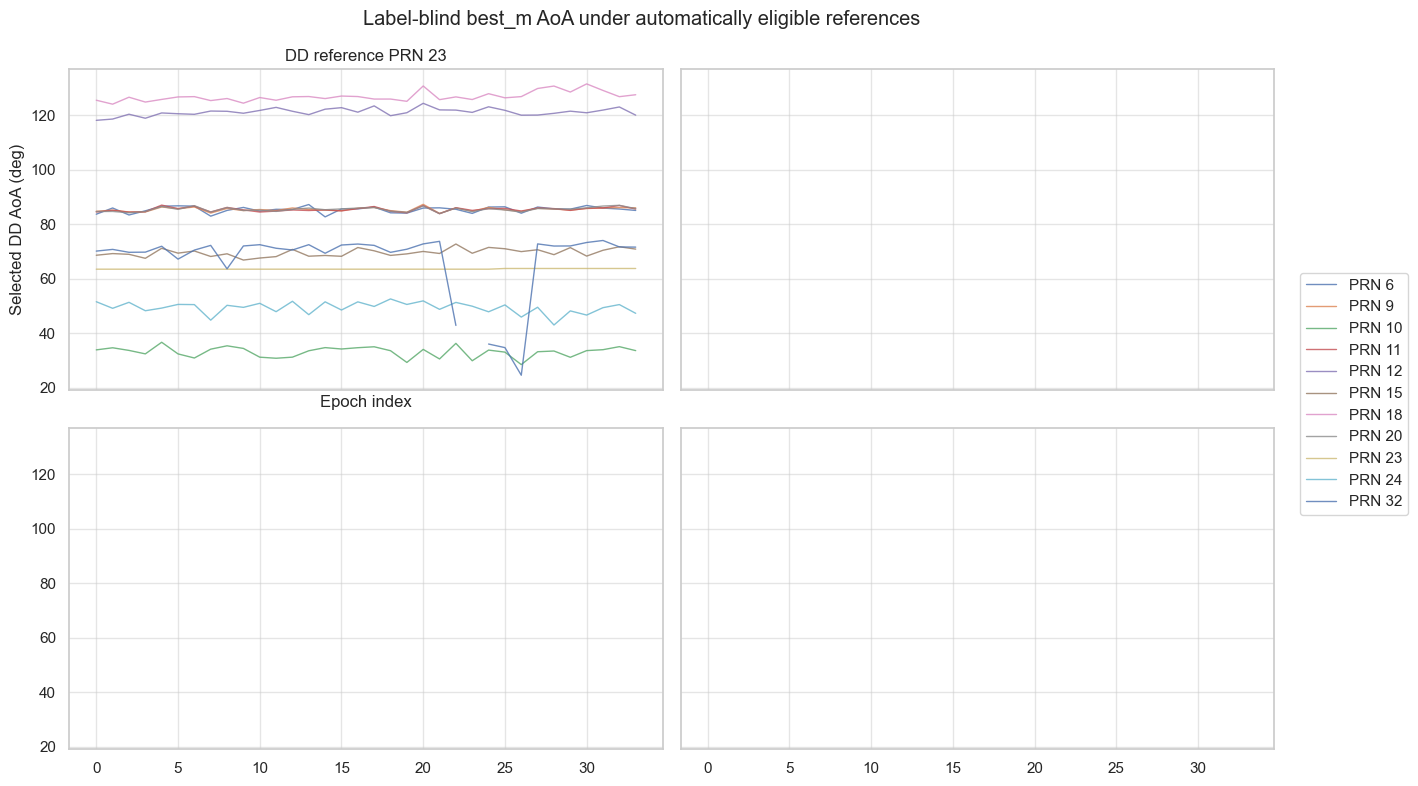

,svid,branch_disagreement_fraction,dp_median_abs_geometry_error,best_m_median_abs_geometry_error,best_m_over_dp_error_ratio
0,6,0.0000,0.1815,0.1815,1.0000
1,9,0.0000,0.0863,0.0863,1.0000
2,10,1.0000,0.8933,0.1067,0.1194
3,11,0.0000,0.5136,0.5136,1.0000
4,12,1.0000,0.7879,0.2121,0.2693
5,15,0.0000,0.0776,0.0776,1.0000
6,18,1.0000,1.0290,0.0305,0.0296
7,20,0.0000,0.1784,0.1784,1.0000
8,23,0.0000,0.0000,0.0000,NaN
9,24,1.0000,1.0128,0.0238,0.0235


In [74]:
references_to_plot = sorted(mixed_geometry_tracks.reference_svid.unique())[:4]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, reference_svid in zip(axes.flat, references_to_plot):
    subset = mixed_geometry_tracks.loc[mixed_geometry_tracks.reference_svid.eq(reference_svid)]
    for svid, track in subset.groupby("svid"):
        ax.plot(track.epoch_index, track.dd_aoa_deg, lw=1.0, alpha=0.8, label=f"PRN {int(svid)}")
    ax.set_title(f"DD reference PRN {int(reference_svid)}")
    ax.set_xlabel("Epoch index")
    ax.set_ylabel("Selected DD AoA (deg)")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1)
fig.suptitle(f"Label-blind {BRANCH_SELECTION_METHOD} AoA under automatically eligible references")
fig.tight_layout()
show_figure(fig, f"mixed_multi_reference_{BRANCH_SELECTION_METHOD}_tracks.png")

branch_ablation_diagnostics = pd.DataFrame()
if not dp_comparison_geometry_tracks.empty:
    keys = ["reference_svid", "epoch_index", "svid"]
    branch_comparison = dp_comparison_geometry_tracks[keys + ["selected_branch"]].merge(
        mixed_geometry_tracks[keys + ["selected_branch"]],
        on=keys, how="inner", suffixes=("_dp", "_best_m"),
    ).dropna(subset=["selected_branch_dp", "selected_branch_best_m"])
    branch_disagreement = branch_comparison.assign(
        branch_disagrees=lambda frame: frame.selected_branch_dp.ne(frame.selected_branch_best_m)
    ).groupby("svid").branch_disagrees.mean().rename("branch_disagreement_fraction")
    dp_error = dp_comparison_geometry_tracks.assign(
        absolute_geometry_error=lambda frame: frame.signed_geometry_error.abs()
    ).groupby("svid").absolute_geometry_error.median().rename("dp_median_abs_geometry_error")
    best_m_error = mixed_geometry_tracks.assign(
        absolute_geometry_error=lambda frame: frame.signed_geometry_error.abs()
    ).groupby("svid").absolute_geometry_error.median().rename("best_m_median_abs_geometry_error")
    branch_ablation_diagnostics = pd.concat([branch_disagreement, dp_error, best_m_error], axis=1).reset_index()
    branch_ablation_diagnostics["best_m_over_dp_error_ratio"] = (
        branch_ablation_diagnostics.best_m_median_abs_geometry_error
        / branch_ablation_diagnostics.dp_median_abs_geometry_error
    )
    display(branch_ablation_diagnostics.round(4))

## Select the pairwise threshold

The notebook uses `PAIRWISE_RESIDUAL_THRESHOLD_DEG` directly as $\tau_p$ in degrees. There is no fitted GMM and no calibration dependency. Change the value in the configuration cell and rerun all cells to test another threshold.

,threshold_source,branch_selection_method,selected_pairwise_threshold_deg
0,static configuration,best_m,10.0


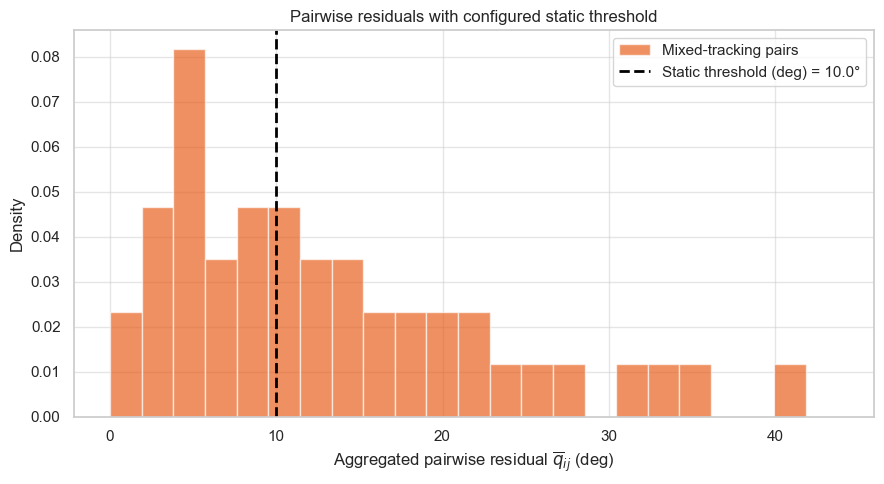

In [75]:
pairwise_threshold = float(PAIRWISE_RESIDUAL_THRESHOLD_DEG)
threshold_label = "Static threshold (deg)"
threshold_summary = pd.DataFrame([{
    "threshold_source": "static configuration",
    "branch_selection_method": BRANCH_SELECTION_METHOD,
    "selected_pairwise_threshold_deg": pairwise_threshold,
}])
display(threshold_summary)

fig, ax = plt.subplots(figsize=(9, 5))
mixed_values = mixed_aggregated_residuals.aggregated_pairwise_residual.astype(float)
bins = np.linspace(0, mixed_values.max() * 1.05, 24)
ax.hist(mixed_values, bins=bins, density=True, alpha=0.65, label="Mixed-tracking pairs", color="#e6550d")
ax.axvline(pairwise_threshold, color="black", ls="--", lw=2, label=f"{threshold_label} = {pairwise_threshold:.1f}°")
ax.set_xlabel(r"Aggregated pairwise residual $\overline{q}_{ij}$ (deg)")
ax.set_ylabel("Density")
ax.set_title("Pairwise residuals with configured static threshold")
ax.legend()
fig.tight_layout()
show_figure(fig, "pairwise_residual_distribution_and_threshold.png")

## Every mixed-tracking pairwise residual

The table and figures below expose every degree-domain $\overline q_{ij}$ value, the number of contributing DD references, and its comparison with the configured static threshold. `mutually_consistent` means $\overline q_{ij}[^{\circ}] \leq \tau_p[^{\circ}]$.

In [76]:
pairwise_value_table = mixed_aggregated_residuals.copy()
pairwise_value_table["branch_selection_method"] = BRANCH_SELECTION_METHOD
pairwise_value_table["aggregated_pairwise_residual_deg"] = pairwise_value_table.aggregated_pairwise_residual
pairwise_value_table["selected_threshold_deg"] = pairwise_threshold
pairwise_value_table["mutually_consistent"] = pairwise_value_table.aggregated_pairwise_residual.le(pairwise_threshold)
pairwise_value_table["threshold_margin_deg"] = pairwise_threshold - pairwise_value_table.aggregated_pairwise_residual
pairwise_value_table = pairwise_value_table.sort_values("aggregated_pairwise_residual").reset_index(drop=True)
display(pairwise_value_table[["pair", "branch_selection_method", "residual_unit", "aggregated_pairwise_residual_deg", "selected_threshold_deg", "threshold_margin_deg", "mutually_consistent", "reference_count", "epoch_observation_count"]].round(3))

,pair,branch_selection_method,residual_unit,aggregated_pairwise_residual_deg,selected_threshold_deg,threshold_margin_deg,mutually_consistent,reference_count,epoch_observation_count
0,PRN 6–PRN 20,best_m,deg,0.524,10.0,9.476,True,1,30
1,PRN 9–PRN 15,best_m,deg,0.973,10.0,9.027,True,1,30
2,PRN 18–PRN 32,best_m,deg,2.904,10.0,7.096,True,1,33
3,PRN 6–PRN 12,best_m,deg,3.335,10.0,6.665,True,1,30
4,PRN 12–PRN 20,best_m,deg,3.493,10.0,6.507,True,1,30
5,PRN 9–PRN 24,best_m,deg,3.778,10.0,6.222,True,1,30
6,PRN 18–PRN 24,best_m,deg,3.920,10.0,6.080,True,1,34
7,PRN 15–PRN 24,best_m,deg,4.386,10.0,5.614,True,1,34
8,PRN 6–PRN 15,best_m,deg,4.964,10.0,5.036,True,1,30
9,PRN 15–PRN 20,best_m,deg,5.198,10.0,4.802,True,1,30


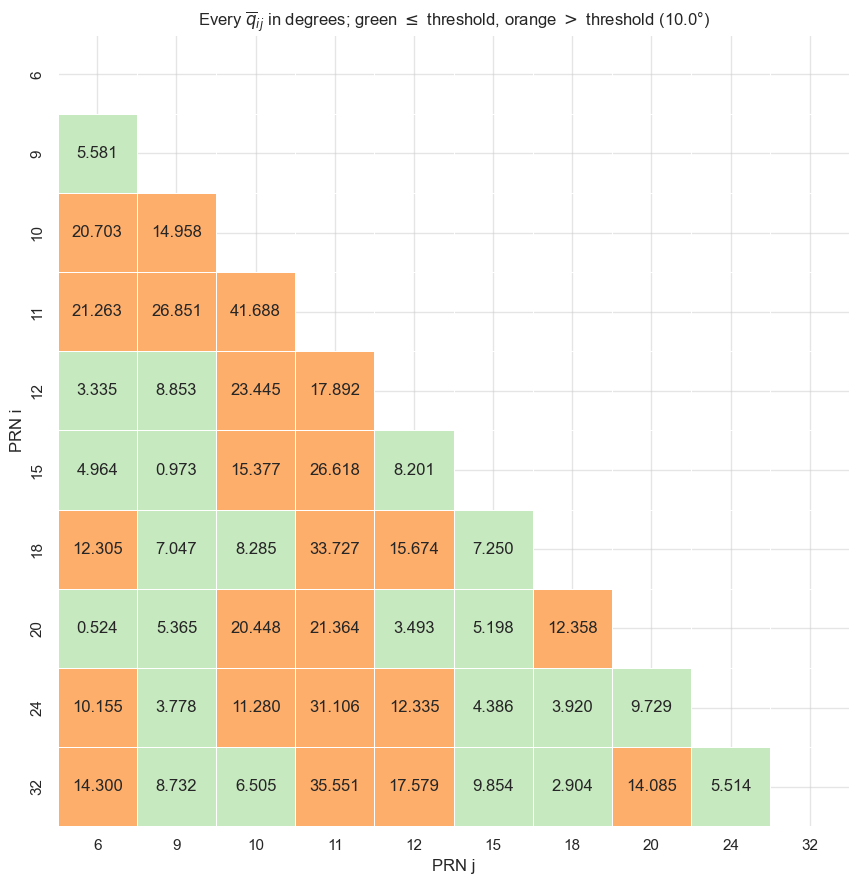

In [77]:
_, residual_matrix_preview, _ = classify_pairwise_geometry(
    mixed_aggregated_residuals,
    pairwise_threshold=pairwise_threshold,
    score_threshold=CONSISTENCY_SCORE_THRESHOLD,
)
status_matrix = residual_matrix_preview.gt(pairwise_threshold).astype(float)
mask = np.triu(np.ones_like(status_matrix, dtype=bool), k=0)
annotations = residual_matrix_preview.map(lambda value: "" if pd.isna(value) else f"{value:.3f}")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    status_matrix, mask=mask, annot=annotations, fmt="",
    cmap=ListedColormap(["#c7e9c0", "#fdae6b"]), vmin=0, vmax=1,
    linewidths=0.7, linecolor="white", cbar=False, square=True, ax=ax,
)
ax.set_title(fr"Every $\overline{{q}}_{{ij}}$ in degrees; green $\leq$ threshold, orange $>$ threshold ({pairwise_threshold:.1f}°)")
ax.set_xlabel("PRN j")
ax.set_ylabel("PRN i")
fig.tight_layout()
show_figure(fig, "mixed_aggregated_pairwise_residual_heatmap.png")

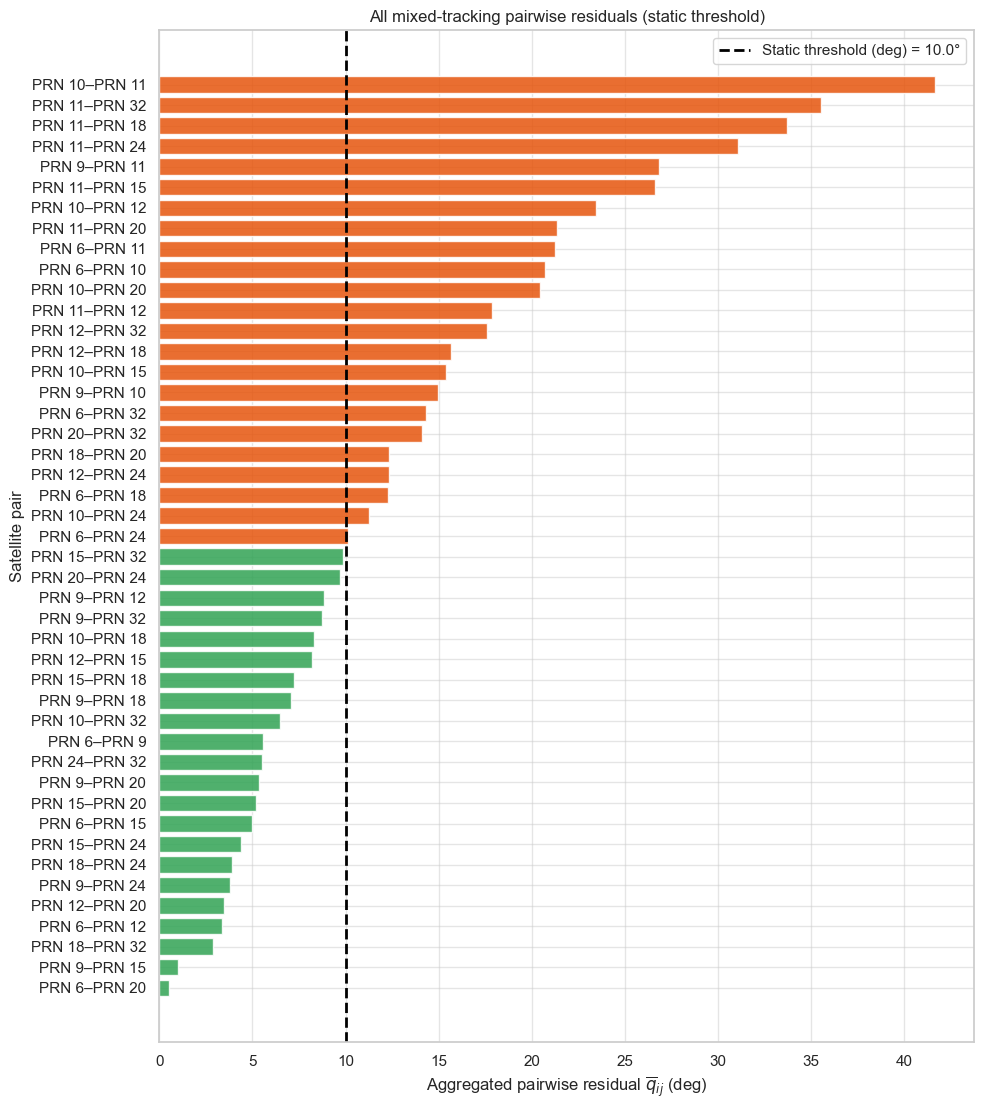

In [78]:
plot_pairs = pairwise_value_table.sort_values("aggregated_pairwise_residual", ascending=True)
colors = np.where(plot_pairs.mutually_consistent, "#31a354", "#e6550d")
fig, ax = plt.subplots(figsize=(10, max(10, 0.25 * len(plot_pairs))))
ax.barh(plot_pairs.pair, plot_pairs.aggregated_pairwise_residual, color=colors, alpha=0.85)
ax.axvline(pairwise_threshold, color="black", ls="--", lw=2, label=f"{threshold_label} = {pairwise_threshold:.1f}°")
ax.set_xlabel(r"Aggregated pairwise residual $\overline{q}_{ij}$ (deg)")
ax.set_ylabel("Satellite pair")
ax.set_title("All mixed-tracking pairwise residuals (static threshold)")
ax.legend()
fig.tight_layout()
show_figure(fig, "mixed_pairwise_residual_values_and_threshold.png")

## Satellite-level consistency grouping

The consistency score uses the journal denominator $|S|-1$. A satellite is left `Undetermined` rather than silently called counterfeit if any required pair is unavailable. Best-m and DP are evaluated with exactly the same configured degree threshold; no ground-truth PRN list is present in this computation.

,svid,consistent_pair_count,valid_pair_count,possible_pair_count,pair_coverage,consistency_score,available_pair_score,pairwise_threshold_deg,score_threshold,decision,reported_group
0,9,7,9,9,1.0,0.7778,0.7778,10.0,0.5,Authentic,Authentic
1,15,7,9,9,1.0,0.7778,0.7778,10.0,0.5,Authentic,Authentic
2,18,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic,Authentic
3,20,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic,Authentic
4,24,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic,Authentic
5,32,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic,Authentic
6,6,4,9,9,1.0,0.4444,0.4444,10.0,0.5,Counterfeit,Counterfeit
7,12,4,9,9,1.0,0.4444,0.4444,10.0,0.5,Counterfeit,Counterfeit
8,10,2,9,9,1.0,0.2222,0.2222,10.0,0.5,Counterfeit,Counterfeit
9,11,0,9,9,1.0,0.0000,0.0000,10.0,0.5,Counterfeit,Counterfeit


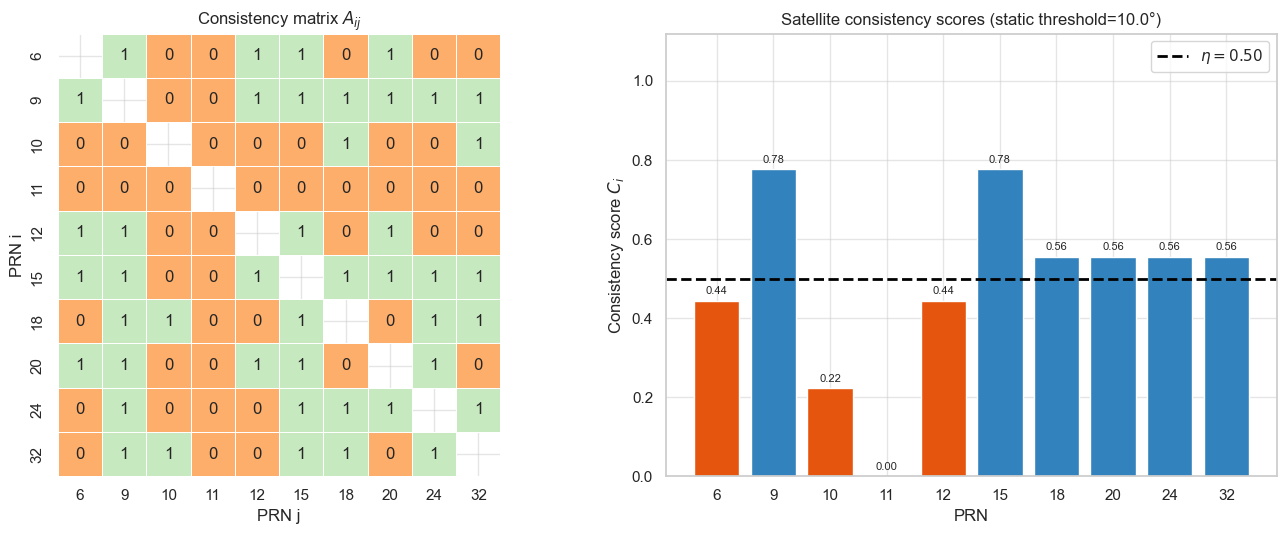

Reported groups (computed without labels):
  Authentic: (9, 15, 18, 20, 24, 32)
  Counterfeit: (6, 10, 11, 12)


In [79]:
classification_scores, residual_matrix, consistency_matrix = classify_pairwise_geometry(
    mixed_aggregated_residuals,
    pairwise_threshold=pairwise_threshold,
    score_threshold=CONSISTENCY_SCORE_THRESHOLD,
    min_pair_coverage=1.0,
)
classification_scores = classification_scores.rename(
    columns={"pairwise_threshold": "pairwise_threshold_deg"}
)
branch_ablation_score_sets = [{
    "branch_selection": BRANCH_SELECTION_METHOD,
    "threshold_source": "static",
    "threshold": pairwise_threshold,
    "scores": classification_scores,
}]
if not dp_comparison_aggregated_residuals.empty:
    dp_static_scores, _, _ = classify_pairwise_geometry(
        dp_comparison_aggregated_residuals, pairwise_threshold=pairwise_threshold,
        score_threshold=CONSISTENCY_SCORE_THRESHOLD, min_pair_coverage=1.0,
    )
    branch_ablation_score_sets.append({
        "branch_selection": "dp", "threshold_source": "static",
        "threshold": pairwise_threshold, "scores": dp_static_scores,
    })
classification_scores["reported_group"] = classification_scores.decision
display(classification_scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(consistency_matrix, annot=True, fmt=".0f", cmap=ListedColormap(["#fdae6b", "#c7e9c0"]), vmin=0, vmax=1, linewidths=0.5, cbar=False, square=True, ax=axes[0])
axes[0].set_title(r"Consistency matrix $A_{ij}$")
axes[0].set_xlabel("PRN j")
axes[0].set_ylabel("PRN i")
score_plot = classification_scores.sort_values("svid")
decision_colors = {"Authentic": "#3182bd", "Counterfeit": "#e6550d", "Undetermined": "#969696"}
bars = axes[1].bar(score_plot.svid.astype(str), score_plot.consistency_score, color=score_plot.decision.map(decision_colors))
axes[1].bar_label(bars, labels=[f"{score:.2f}" for score in score_plot.consistency_score], padding=3, fontsize=8)
axes[1].axhline(CONSISTENCY_SCORE_THRESHOLD, color="black", ls="--", lw=2, label=fr"$\eta={CONSISTENCY_SCORE_THRESHOLD:.2f}$")
axes[1].set_ylim(0, 1.12)
axes[1].set_xlabel("PRN")
axes[1].set_ylabel(r"Consistency score $C_i$")
axes[1].set_title(f"Satellite consistency scores (static threshold={pairwise_threshold:.1f}°)")
axes[1].legend()
fig.tight_layout()
show_figure(fig, "mixed_consistency_matrix_and_scores.png")

predicted_groups = classification_scores.groupby("reported_group")["svid"].apply(lambda values: tuple(sorted(map(int, values)))).to_dict()
print("Reported groups (computed without labels):")
for group_name, svids in predicted_groups.items():
    print(f"  {group_name}: {svids}")

## Post-hoc controlled-experiment evaluation

Only now, after groups are frozen, are the NAVISIM configuration labels introduced. They are used solely to diagnose whether the configured static threshold happens to separate the two physical groups; they never affect ordinary best-m/DP references, branches, pairwise values, scores, or decisions.

In [80]:
CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS = frozenset({6, 9, 11, 20})  # Evaluation only.
evaluation = classification_scores.copy()
evaluation["ground_truth"] = evaluation.svid.map(lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic")
evaluation["correct"] = evaluation.decision.eq(evaluation.ground_truth)
display(evaluation[["svid", "consistency_score", "decision", "ground_truth", "correct"]].sort_values("svid"))
display(pd.crosstab(evaluation.ground_truth, evaluation.decision, margins=True))

authentic_rows = evaluation.ground_truth.eq("Authentic")
counterfeit_rows = evaluation.ground_truth.eq("Counterfeit")
authentic_acceptance = evaluation.loc[authentic_rows, "decision"].eq("Authentic").mean()
counterfeit_detection = evaluation.loc[counterfeit_rows, "decision"].eq("Counterfeit").mean()
evaluation_summary = pd.DataFrame([{
    "branch_selection_method": BRANCH_SELECTION_METHOD,
    "authentic_acceptance_percent": 100 * authentic_acceptance,
    "counterfeit_detection_percent": 100 * counterfeit_detection,
    "balanced_accuracy_percent": 50 * (authentic_acceptance + counterfeit_detection),
    "overall_accuracy_percent": 100 * evaluation.correct.mean(),
    "predicted_group_count": evaluation.decision.nunique(),
}])
display(evaluation_summary.round(2))

ablation_rows = []
for score_set in branch_ablation_score_sets:
    scored = score_set["scores"].copy()
    scored["ground_truth"] = scored.svid.map(
        lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic"
    )
    authentic_mask = scored.ground_truth.eq("Authentic")
    counterfeit_mask = scored.ground_truth.eq("Counterfeit")
    authentic_rate = scored.loc[authentic_mask, "decision"].eq("Authentic").mean()
    counterfeit_rate = scored.loc[counterfeit_mask, "decision"].eq("Counterfeit").mean()
    ablation_rows.append({
        "branch_selection": score_set["branch_selection"],
        "threshold_source": score_set["threshold_source"],
        "threshold_deg": score_set["threshold"],
        "authentic_accepted": int(scored.loc[authentic_mask, "decision"].eq("Authentic").sum()),
        "authentic_total": int(authentic_mask.sum()),
        "counterfeit_detected": int(scored.loc[counterfeit_mask, "decision"].eq("Counterfeit").sum()),
        "counterfeit_total": int(counterfeit_mask.sum()),
        "authentic_acceptance_percent": 100 * authentic_rate,
        "counterfeit_detection_percent": 100 * counterfeit_rate,
        "balanced_accuracy_percent": 50 * (authentic_rate + counterfeit_rate),
    })
branch_ablation_evaluation = pd.DataFrame(ablation_rows).sort_values(
    ["threshold_source", "branch_selection"]
).reset_index(drop=True)
display(branch_ablation_evaluation.round(2))

result_prefix = f"The static-threshold classifier (tau_p={pairwise_threshold:.1f} deg)"
if evaluation.decision.nunique() < 2:
    print(f"RESULT: {result_prefix} does not separate two groups in this run.")
elif evaluation.correct.all():
    print(f"RESULT: {result_prefix} separates both controlled groups in this run.")
else:
    print(f"RESULT: {result_prefix} produces two groups, but does not recover all controlled physical labels.")
if BRANCH_SELECTION_METHOD == "best_m":
    print(
        f"BEST-M ABLATION: authentic acceptance={100 * authentic_acceptance:.2f}%, "
        f"spoof detection={100 * counterfeit_detection:.2f}%. "
        "Best-m is applied to all unknown PRNs; it must not be interpreted as a blind detector."
    )

,svid,consistency_score,decision,ground_truth,correct
6,6,0.444444,Counterfeit,Counterfeit,True
0,9,0.777778,Authentic,Counterfeit,False
8,10,0.222222,Counterfeit,Authentic,False
9,11,0.000000,Counterfeit,Counterfeit,True
7,12,0.444444,Counterfeit,Authentic,False
1,15,0.777778,Authentic,Authentic,True
2,18,0.555556,Authentic,Authentic,True
3,20,0.555556,Authentic,Counterfeit,False
4,24,0.555556,Authentic,Authentic,True
5,32,0.555556,Authentic,Authentic,True


decision,Authentic,Counterfeit,All
ground_truth,,,
Authentic,4,2,6
Counterfeit,2,2,4
All,6,4,10


,branch_selection_method,authentic_acceptance_percent,counterfeit_detection_percent,balanced_accuracy_percent,overall_accuracy_percent,predicted_group_count
0,best_m,66.67,50.0,58.33,60.0,2


,branch_selection,threshold_source,threshold_deg,authentic_accepted,authentic_total,counterfeit_detected,counterfeit_total,authentic_acceptance_percent,counterfeit_detection_percent,balanced_accuracy_percent
0,best_m,static,10.0,4,6,2,4,66.67,50.0,58.33
1,dp,static,10.0,0,6,4,4,0.00,100.0,50.00


RESULT: The static-threshold classifier (tau_p=10.0 deg) produces two groups, but does not recover all controlled physical labels.
BEST-M ABLATION: authentic acceptance=66.67%, spoof detection=50.00%. Best-m is applied to all unknown PRNs; it must not be interpreted as a blind detector.


## Oracle hybrid upper bound: best-m authentic, DP counterfeit

This deliberately non-blind diagnostic uses the controlled identities during reconstruction: authentic targets take their ephemeris-aligned constant best-m tracks, while counterfeit targets retain their temporal-DP tracks. It then recomputes the degree-domain pairwise residual aggregation and applies the same configured static degree threshold as the other reconstructions. The purpose is only to test whether ideal knowledge of which ambiguity selector to use makes the threshold classifier separable; it cannot be reported as a detector.

,threshold_source,branch_selection_method,selected_pairwise_threshold_deg
0,static configuration,oracle_hybrid,10.0


,svid,consistent_pair_count,valid_pair_count,possible_pair_count,pair_coverage,consistency_score,available_pair_score,pairwise_threshold_deg,score_threshold,decision
0,9,7,9,9,1.0,0.7778,0.7778,10.0,0.5,Authentic
1,15,7,9,9,1.0,0.7778,0.7778,10.0,0.5,Authentic
2,18,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic
3,20,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic
4,24,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic
5,32,5,9,9,1.0,0.5556,0.5556,10.0,0.5,Authentic
6,6,4,9,9,1.0,0.4444,0.4444,10.0,0.5,Counterfeit
7,12,4,9,9,1.0,0.4444,0.4444,10.0,0.5,Counterfeit
8,10,2,9,9,1.0,0.2222,0.2222,10.0,0.5,Counterfeit
9,11,0,9,9,1.0,0.0000,0.0000,10.0,0.5,Counterfeit


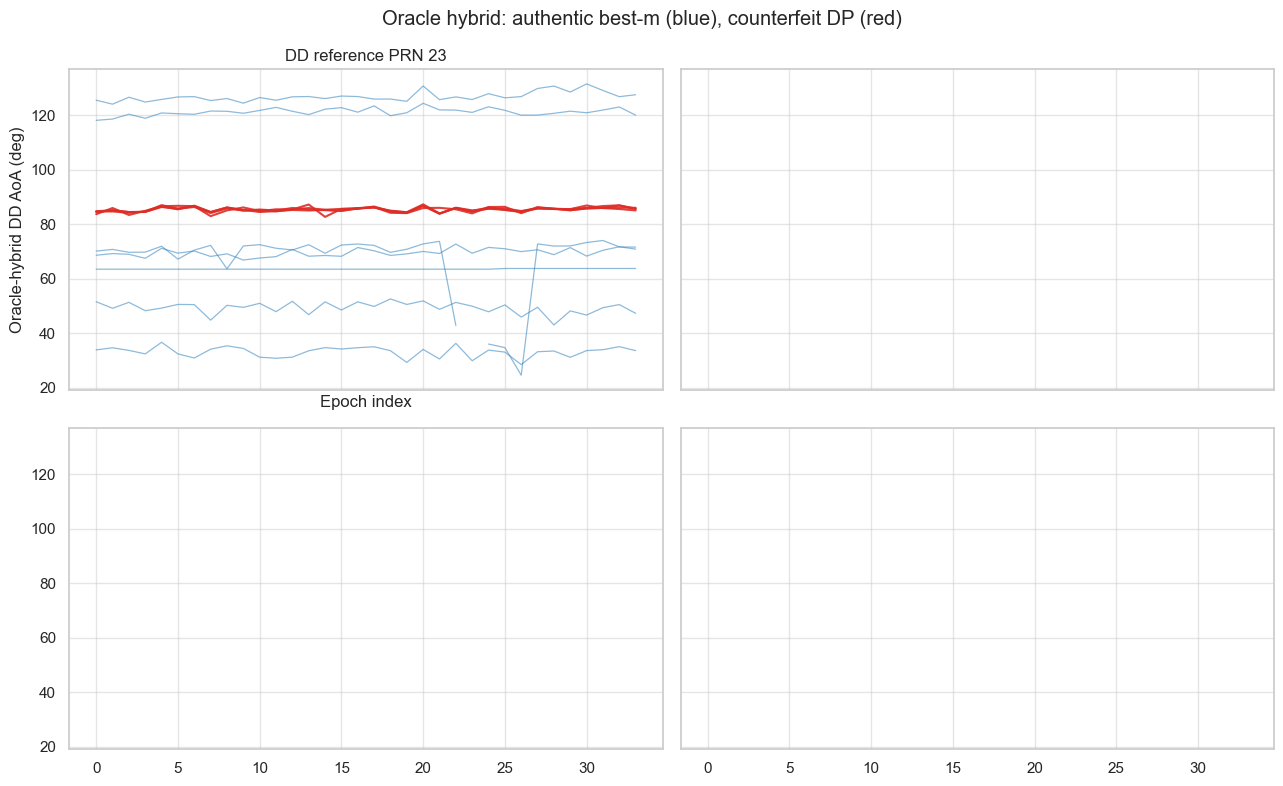

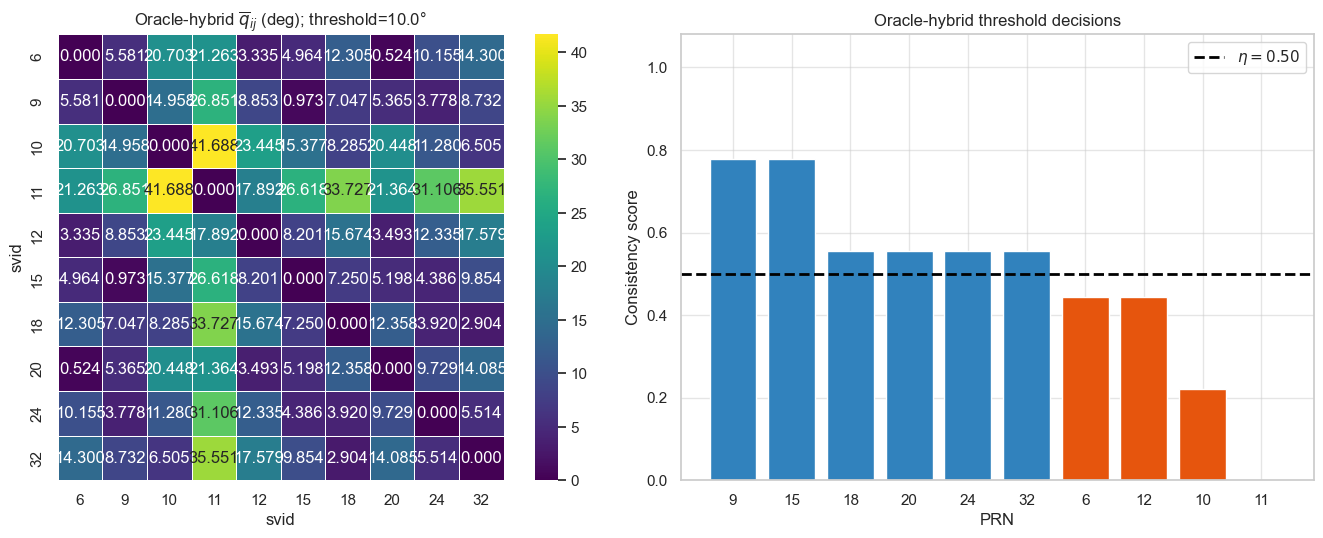

In [81]:
oracle_hybrid_geometry_tracks = pd.concat([
    mixed_geometry_tracks.loc[~mixed_geometry_tracks.svid.isin(CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS)],
    dp_comparison_geometry_tracks.loc[dp_comparison_geometry_tracks.svid.isin(CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS)],
], ignore_index=True).sort_values(["reference_svid", "epoch_index", "svid"]).reset_index(drop=True)
oracle_hybrid_geometry_tracks = oracle_hybrid_geometry_tracks.rename(
    columns={"branch_selection_method": "target_branch_selector"}
)
oracle_hybrid_geometry_tracks.insert(1, "branch_selection_method", "oracle_hybrid")

oracle_hybrid_epoch_residuals = compute_pairwise_geometry_residuals(
    oracle_hybrid_geometry_tracks, residual_domain="degrees"
)
oracle_hybrid_residuals_by_reference, oracle_hybrid_aggregated_residuals = aggregate_pairwise_geometry_residuals(
    oracle_hybrid_epoch_residuals,
    min_epochs_per_reference=MIN_PAIR_EPOCHS_PER_REFERENCE,
    min_references_per_pair=MIN_REFERENCES_PER_PAIR,
)
oracle_hybrid_threshold = pairwise_threshold
oracle_hybrid_threshold_summary = pd.DataFrame([{
    "threshold_source": "static configuration",
    "branch_selection_method": "oracle_hybrid",
    "selected_pairwise_threshold_deg": oracle_hybrid_threshold,
}])
display(oracle_hybrid_threshold_summary.round(6))

oracle_hybrid_scores, oracle_hybrid_residual_matrix, oracle_hybrid_consistency_matrix = classify_pairwise_geometry(
    oracle_hybrid_aggregated_residuals,
    pairwise_threshold=oracle_hybrid_threshold,
    score_threshold=CONSISTENCY_SCORE_THRESHOLD,
    min_pair_coverage=1.0,
)
oracle_hybrid_scores = oracle_hybrid_scores.rename(
    columns={"pairwise_threshold": "pairwise_threshold_deg"}
)
display(oracle_hybrid_scores.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, reference_svid in zip(axes.flat, sorted(oracle_hybrid_geometry_tracks.reference_svid.unique())[:4]):
    subset = oracle_hybrid_geometry_tracks.loc[oracle_hybrid_geometry_tracks.reference_svid.eq(reference_svid)]
    for svid, track in subset.groupby("svid"):
        is_counterfeit = int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS
        ax.plot(
            track.epoch_index, track.dd_aoa_deg,
            color="#de2d26" if is_counterfeit else "#3182bd",
            lw=1.5 if is_counterfeit else 0.9, alpha=0.9 if is_counterfeit else 0.55,
        )
    ax.set_title(f"DD reference PRN {int(reference_svid)}")
    ax.set_xlabel("Epoch index")
    ax.set_ylabel("Oracle-hybrid DD AoA (deg)")
fig.suptitle("Oracle hybrid: authentic best-m (blue), counterfeit DP (red)")
fig.tight_layout()
show_figure(fig, "oracle_hybrid_multi_reference_aoa_tracks.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(
    oracle_hybrid_residual_matrix, annot=True, fmt=".3f", cmap="viridis",
    vmin=0, vmax=max(oracle_hybrid_threshold * 2, oracle_hybrid_residual_matrix.max().max()),
    square=True, linewidths=0.5, ax=axes[0],
)
axes[0].set_title(fr"Oracle-hybrid $\overline{{q}}_{{ij}}$ (deg); threshold={oracle_hybrid_threshold:.1f}°")
decision_colors = {"Authentic": "#3182bd", "Counterfeit": "#e6550d", "Undetermined": "#969696"}
axes[1].bar(
    oracle_hybrid_scores.svid.astype(str), oracle_hybrid_scores.consistency_score,
    color=[decision_colors[value] for value in oracle_hybrid_scores.decision],
)
axes[1].axhline(CONSISTENCY_SCORE_THRESHOLD, color="black", ls="--", lw=2, label=fr"$\eta={CONSISTENCY_SCORE_THRESHOLD:.2f}$")
axes[1].set_ylim(0, 1.08)
axes[1].set_xlabel("PRN")
axes[1].set_ylabel("Consistency score")
axes[1].set_title("Oracle-hybrid threshold decisions")
axes[1].legend()
fig.tight_layout()
show_figure(fig, "oracle_hybrid_residuals_and_scores.png")

In [82]:
oracle_hybrid_evaluation = oracle_hybrid_scores.copy()
oracle_hybrid_evaluation["ground_truth"] = oracle_hybrid_evaluation.svid.map(
    lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic"
)
oracle_hybrid_evaluation["correct"] = oracle_hybrid_evaluation.decision.eq(
    oracle_hybrid_evaluation.ground_truth
)
display(oracle_hybrid_evaluation[["svid", "consistency_score", "decision", "ground_truth", "correct"]].sort_values("svid"))
display(pd.crosstab(oracle_hybrid_evaluation.ground_truth, oracle_hybrid_evaluation.decision, margins=True))
oracle_authentic = oracle_hybrid_evaluation.ground_truth.eq("Authentic")
oracle_counterfeit = oracle_hybrid_evaluation.ground_truth.eq("Counterfeit")
oracle_authentic_rate = oracle_hybrid_evaluation.loc[oracle_authentic, "correct"].mean()
oracle_counterfeit_rate = oracle_hybrid_evaluation.loc[oracle_counterfeit, "correct"].mean()
oracle_hybrid_summary = pd.DataFrame([{
    "pairwise_threshold_deg": oracle_hybrid_threshold,
    "score_threshold": CONSISTENCY_SCORE_THRESHOLD,
    "authentic_accepted": int(oracle_hybrid_evaluation.loc[oracle_authentic, "correct"].sum()),
    "authentic_total": int(oracle_authentic.sum()),
    "counterfeit_detected": int(oracle_hybrid_evaluation.loc[oracle_counterfeit, "correct"].sum()),
    "counterfeit_total": int(oracle_counterfeit.sum()),
    "authentic_acceptance_percent": 100 * oracle_authentic_rate,
    "counterfeit_detection_percent": 100 * oracle_counterfeit_rate,
    "balanced_accuracy_percent": 50 * (oracle_authentic_rate + oracle_counterfeit_rate),
    "overall_accuracy_percent": 100 * oracle_hybrid_evaluation.correct.mean(),
}])
display(oracle_hybrid_summary.round(4))

oracle_method_rows = []
for score_set in branch_ablation_score_sets:
    scored = score_set["scores"].copy()
    truth = scored.svid.map(
        lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic"
    )
    authentic_mask = truth.eq("Authentic")
    counterfeit_mask = truth.eq("Counterfeit")
    oracle_method_rows.append({
        "reconstruction": score_set["branch_selection"],
        "pairwise_threshold_deg": pairwise_threshold,
        "authentic_acceptance_percent": 100 * scored.loc[authentic_mask, "decision"].eq("Authentic").mean(),
        "counterfeit_detection_percent": 100 * scored.loc[counterfeit_mask, "decision"].eq("Counterfeit").mean(),
    })
oracle_method_rows.append({
    "reconstruction": "oracle hybrid (label-leaking)",
    "pairwise_threshold_deg": oracle_hybrid_threshold,
    "authentic_acceptance_percent": 100 * oracle_authentic_rate,
    "counterfeit_detection_percent": 100 * oracle_counterfeit_rate,
})
oracle_method_comparison = pd.DataFrame(oracle_method_rows)
oracle_method_comparison["balanced_accuracy_percent"] = (
    oracle_method_comparison.authentic_acceptance_percent
    + oracle_method_comparison.counterfeit_detection_percent
) / 2
display(oracle_method_comparison.round(4))

oracle_groups = oracle_hybrid_scores.groupby("decision").svid.apply(
    lambda values: tuple(sorted(map(int, values)))
).to_dict()
print(f"Oracle-hybrid groups at static threshold {oracle_hybrid_threshold:.1f} deg: {oracle_groups}")
if oracle_hybrid_evaluation.correct.all():
    print("RESULT: The oracle hybrid makes the pairwise threshold classifier exactly separable.")
else:
    print("RESULT: Even with true identities used to choose best-m versus DP, the pairwise threshold classifier does not recover both physical groups.")

,svid,consistency_score,decision,ground_truth,correct
6,6,0.444444,Counterfeit,Counterfeit,True
0,9,0.777778,Authentic,Counterfeit,False
8,10,0.222222,Counterfeit,Authentic,False
9,11,0.000000,Counterfeit,Counterfeit,True
7,12,0.444444,Counterfeit,Authentic,False
1,15,0.777778,Authentic,Authentic,True
2,18,0.555556,Authentic,Authentic,True
3,20,0.555556,Authentic,Counterfeit,False
4,24,0.555556,Authentic,Authentic,True
5,32,0.555556,Authentic,Authentic,True


decision,Authentic,Counterfeit,All
ground_truth,,,
Authentic,4,2,6
Counterfeit,2,2,4
All,6,4,10


,pairwise_threshold_deg,score_threshold,authentic_accepted,authentic_total,counterfeit_detected,counterfeit_total,authentic_acceptance_percent,counterfeit_detection_percent,balanced_accuracy_percent,overall_accuracy_percent
0,10.0,0.5,4,6,2,4,66.6667,50.0,58.3333,60.0


,reconstruction,pairwise_threshold_deg,authentic_acceptance_percent,counterfeit_detection_percent,balanced_accuracy_percent
0,best_m,10.0,66.6667,50.0,58.3333
1,dp,10.0,0.0000,100.0,50.0000
2,oracle hybrid (label-leaking),10.0,66.6667,50.0,58.3333


Oracle-hybrid groups at static threshold 10.0 deg: {'Authentic': (9, 15, 18, 20, 24, 32), 'Counterfeit': (6, 10, 11, 12)}
RESULT: Even with true identities used to choose best-m versus DP, the pairwise threshold classifier does not recover both physical groups.


In [83]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    mixed_geometry_tracks.to_csv(OUTPUT_DIR / f"mixed_multi_reference_{BRANCH_SELECTION_METHOD}_tracks.csv", index=False)
    mixed_epoch_residuals.to_csv(OUTPUT_DIR / "mixed_pairwise_residuals_by_epoch_reference.csv", index=False)
    mixed_residuals_by_reference.to_csv(OUTPUT_DIR / "mixed_pairwise_residuals_by_reference.csv", index=False)
    pairwise_value_table.to_csv(OUTPUT_DIR / "mixed_aggregated_pairwise_residuals_with_threshold.csv", index=False)
    residual_matrix.to_csv(OUTPUT_DIR / "mixed_pairwise_residual_matrix.csv")
    consistency_matrix.to_csv(OUTPUT_DIR / "mixed_consistency_matrix.csv")
    classification_scores.to_csv(OUTPUT_DIR / "mixed_blind_classification_scores.csv", index=False)
    evaluation.to_csv(OUTPUT_DIR / "mixed_posthoc_controlled_evaluation.csv", index=False)
    threshold_summary.to_csv(OUTPUT_DIR / "static_pairwise_threshold_deg.csv", index=False)
    branch_ablation_diagnostics.to_csv(OUTPUT_DIR / "dp_vs_best_m_branch_diagnostics.csv", index=False)
    branch_ablation_evaluation.to_csv(OUTPUT_DIR / "dp_vs_best_m_static_threshold_evaluation.csv", index=False)
    oracle_hybrid_geometry_tracks.to_csv(OUTPUT_DIR / "oracle_hybrid_geometry_tracks.csv", index=False)
    oracle_hybrid_epoch_residuals.to_csv(OUTPUT_DIR / "oracle_hybrid_pairwise_residuals_by_epoch_reference.csv", index=False)
    oracle_hybrid_residuals_by_reference.to_csv(OUTPUT_DIR / "oracle_hybrid_pairwise_residuals_by_reference.csv", index=False)
    oracle_hybrid_aggregated_residuals.to_csv(OUTPUT_DIR / "oracle_hybrid_aggregated_pairwise_residuals.csv", index=False)
    oracle_hybrid_scores.to_csv(OUTPUT_DIR / "oracle_hybrid_scores.csv", index=False)
    oracle_hybrid_threshold_summary.to_csv(OUTPUT_DIR / "oracle_hybrid_threshold_summary.csv", index=False)
    oracle_method_comparison.to_csv(OUTPUT_DIR / "oracle_hybrid_method_comparison.csv", index=False)
    if not dp_comparison_geometry_tracks.empty:
        dp_comparison_geometry_tracks.to_csv(OUTPUT_DIR / "mixed_multi_reference_dp_ablation_tracks.csv", index=False)
        dp_comparison_epoch_residuals.to_csv(OUTPUT_DIR / "mixed_dp_ablation_pairwise_residuals_by_epoch_reference.csv", index=False)
        dp_comparison_aggregated_residuals.to_csv(OUTPUT_DIR / "mixed_dp_ablation_aggregated_pairwise_residuals.csv", index=False)
    print(f"Saved pairwise-analysis tables to {OUTPUT_DIR}")
else:
    print("SAVE_OUTPUTS=False; inline results were not written to disk.")

SAVE_OUTPUTS=False; inline results were not written to disk.


## Interpretation and required paper caveat

This notebook now computes pairwise geometry residuals directly in degrees and uses only the static `PAIRWISE_RESIDUAL_THRESHOLD_DEG` configured near the top. The value is not fitted from the mixed data and no authentic-calibration recording is loaded. Change that one degree value and rerun all cells; the residual tables, heatmaps, consistency matrices, and evaluation tables will update with the same threshold for best-m, DP, and the oracle hybrid.

The configured threshold is for experimentation, not a publication-grade decision boundary. The controlled counterfeit set `{6, 9, 11, 20}` is used only in the post-hoc evaluation and oracle-hybrid sections; it is not used by the ordinary best-m or DP pairwise classifier. Do not select the final paper threshold by maximizing performance on these same labels.

Best-m and DP now receive the identical $\tau_p$, so their comparison isolates branch reconstruction rather than differences in threshold fitting. Best-m still minimizes error to each target's ephemeris before the pairwise residual compares DD geometry with that same ephemeris, so it can bias unknown counterfeit targets toward apparent consistency. Treat it as a diagnostic rather than a blind spoof detector.

The oracle-hybrid section remains an explicit label-leaking upper bound: it applies best-m to known authentic targets and DP to known counterfeit targets, then uses the same static threshold. Its output is useful for understanding the DD reconstruction but is neither blind nor deployable.